In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [6]:
ROOT = Path('/content/drive/MyDrive/CUST-Iris')

IMG_DIR = ROOT / 'CUST-Iris-V1'
MASK_DIR = ROOT / 'CUST-Iris-V1-Masks'

images = sorted(IMG_DIR.glob('*.jpg'))
masks = sorted(MASK_DIR.glob('*.png'))

print("Images:", len(images))
print("Masks:", len(masks))
print("Image folder exists:", IMG_DIR.exists())
print("Mask folder exists:", MASK_DIR.exists())

print("Number of users:", len(set(p.stem.split('_')[0] for p in images)))

Images: 2880
Masks: 2880
Image folder exists: True
Mask folder exists: True
Number of users: 360


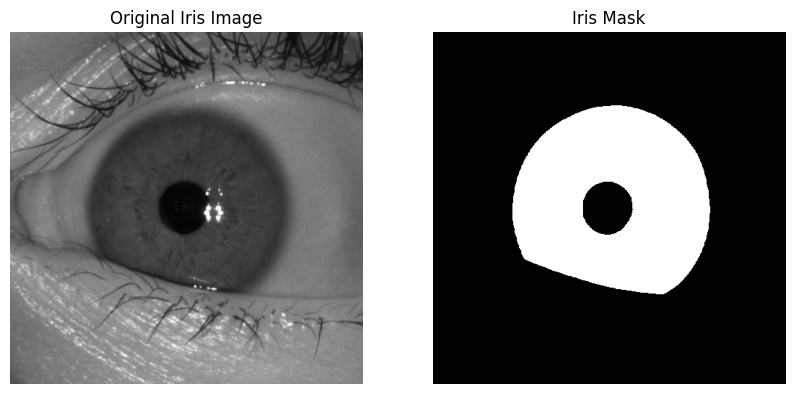

In [7]:
#Hiển thị ảnh mống mắt và mask
image_path = IMG_DIR / '100_1_1.jpg'
mask_path = MASK_DIR / '100_1_1.png'

image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

assert image is not None, "Cannot load iris image"
assert mask is not None, "Cannot load iris mask"

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Iris Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='gray')
plt.title('Iris Mask')
plt.axis('off')

plt.show()

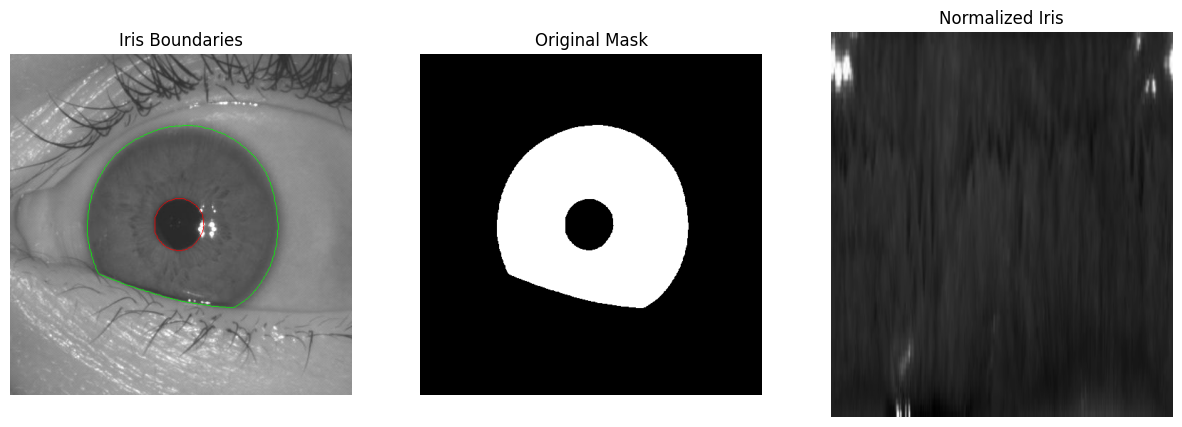

Normalized shape: (64, 512)


In [8]:
def normalize_iris(image, mask, radial_res=64, angular_res=512):
    binary = np.where(mask > 127, 255, 0).astype(np.uint8)

    contours, hierarchy = cv2.findContours(
        binary, cv2.RETR_TREE, cv2.CHAIN_APPROX_NONE
    )

    if hierarchy is None:
        raise ValueError("Invalid iris mask")

    outer_idx = max(
        range(len(contours)),
        key=lambda i: cv2.contourArea(contours[i])
    )

    inner_idx = hierarchy[0][outer_idx][2]

    if inner_idx < 0:
        raise ValueError("Cannot find pupil boundary")

    M = cv2.moments(contours[inner_idx])

    if M["m00"] == 0:
        raise ValueError("Invalid pupil contour")

    cx = M["m10"] / M["m00"]
    cy = M["m01"] / M["m00"]

    h, w = image.shape
    angles = np.linspace(0, 2 * np.pi, angular_res, endpoint=False)
    radii = np.arange(0, int(np.hypot(h, w)), 0.5, dtype=np.float32)

    ray_x = (cx + np.cos(angles)[:, None] * radii).astype(np.float32)
    ray_y = (cy + np.sin(angles)[:, None] * radii).astype(np.float32)

    sampled_mask = cv2.remap(
        binary, ray_x, ray_y,
        cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    inner_r = np.zeros(angular_res, dtype=np.float32)
    outer_r = np.zeros(angular_res, dtype=np.float32)

    for i, row in enumerate(sampled_mask):
        indices = np.flatnonzero(row > 0)

        if len(indices) == 0:
            raise ValueError("Invalid iris boundary")

        inner_r[i] = radii[indices[0]]
        outer_r[i] = radii[indices[-1]]

    if np.any(outer_r <= inner_r):
        raise ValueError("Invalid iris region")

    rho = np.linspace(0.05, 0.95, radial_res)[:, None]

    r = inner_r[None, :] + rho * (outer_r - inner_r)[None, :]

    map_x = (cx + np.cos(angles)[None, :] * r).astype(np.float32)
    map_y = (cy + np.sin(angles)[None, :] * r).astype(np.float32)

    normalized = cv2.remap(
        image, map_x, map_y,
        cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    debug = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    cv2.drawContours(debug, [contours[outer_idx]], -1, (0, 255, 0), 1)
    cv2.drawContours(debug, [contours[inner_idx]], -1, (255, 0, 0), 1)

    return normalized, debug
normalized, debug = normalize_iris(image, mask)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(debug)
plt.title("Iris Boundaries")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(normalized, cmap="gray", aspect="auto")
plt.title("Normalized Iris")
plt.axis("off")

plt.show()

print("Normalized shape:", normalized.shape)

Iris Code shape: (64, 512, 2)
Data type: uint8
Unique values: [0 1]
Total bits: 65536


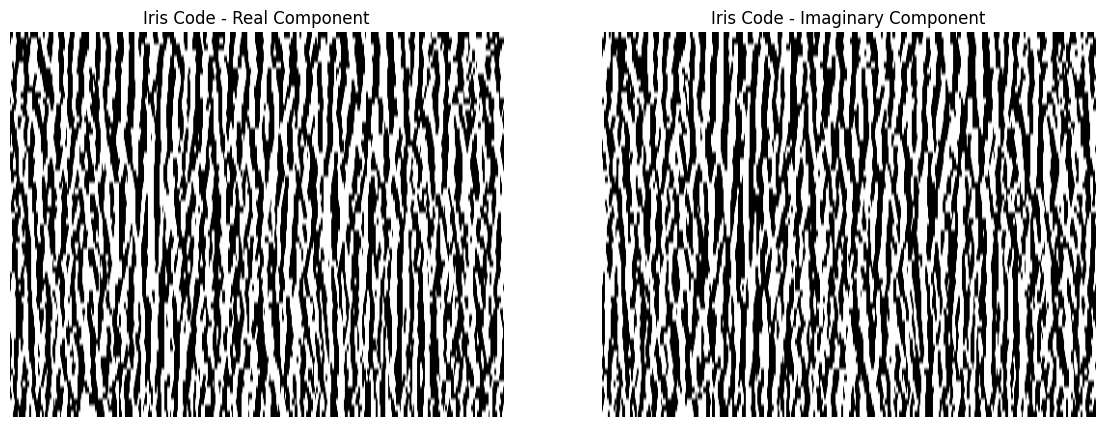

In [9]:
#Chúng ta sử dụng Log-Gabor Filter để trích xuất đặc trưng kết cấu và chuyển chúng thành các bit 0 và 1.
def encode_iris(normalized, f0=0.1, sigma_on_f=0.55):
    image = normalized.astype(np.float32)

    image -= image.mean(axis=1, keepdims=True)

    rows, cols = image.shape

    frequencies = np.fft.fftfreq(cols)
    log_gabor = np.zeros(cols, dtype=np.float32)

    positive = frequencies > 0

    log_gabor[positive] = np.exp(
        -(np.log(frequencies[positive] / f0) ** 2)
        / (2 * np.log(sigma_on_f) ** 2)
    )

    spectrum = np.fft.fft(image, axis=1)
    response = np.fft.ifft(
        spectrum * log_gabor[None, :],
        axis=1
    )

    code = np.stack([
        response.real >= 0,
        response.imag >= 0
    ], axis=-1)

    return code.astype(np.uint8)
iris_code = encode_iris(normalized)

print("Iris Code shape:", iris_code.shape)
print("Data type:", iris_code.dtype)
print("Unique values:", np.unique(iris_code))
print("Total bits:", iris_code.size)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(iris_code[:, :, 0], cmap='gray', aspect='auto')
plt.title("Iris Code - Real Component")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(iris_code[:, :, 1], cmap='gray', aspect='auto')
plt.title("Iris Code - Imaginary Component")
plt.axis("off")

plt.show()

In [10]:
def hamming_distance(code1, code2, max_shift=32):
    if code1.shape != code2.shape:
        raise ValueError("Iris Code dimensions must match")

    distances = []

    for shift in range(-max_shift, max_shift + 1):
        shifted = np.roll(code2, shift, axis=1)
        distance = np.mean(code1 != shifted)
        distances.append((float(distance), shift))

    return min(distances)


In [11]:
def extract_iris_code(stem):
    image_path = IMG_DIR / f"{stem}.jpg"
    mask_path = MASK_DIR / f"{stem}.png"

    if not image_path.exists() or not mask_path.exists():
        raise FileNotFoundError(f"Missing image or mask: {stem}")

    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if img is None or msk is None:
        raise ValueError(f"Cannot read image or mask: {stem}")

    normalized, _ = normalize_iris(img, msk)
    return encode_iris(normalized)
user_id = "100"

same_user_samples = sorted(IMG_DIR.glob(f"{user_id}_1_*.jpg"))

other_sample = next(
    p for p in images
    if p.stem.split("_")[0] != user_id
    and p.stem.split("_")[1:] == ["1", "1"]
)

stem1 = same_user_samples[0].stem
stem2 = same_user_samples[1].stem
stem3 = other_sample.stem

code1 = extract_iris_code(stem1)
code2 = extract_iris_code(stem2)
code3 = extract_iris_code(stem3)

d_self, s_self = hamming_distance(code1, code1)
d_same, s_same = hamming_distance(code1, code2)
d_diff, s_diff = hamming_distance(code1, code3)

print("Same image:", d_self, "Shift:", s_self)
print("Same person:", d_same, "Shift:", s_same)
print("Different person:", d_diff, "Shift:", s_diff)

Same image: 0.0 Shift: 0
Same person: 0.287445068359375 Shift: 0
Different person: 0.488555908203125 Shift: 10


In [12]:
users = [str(i) for i in range(100, 110)]

iris_database = {}

for user in users:
    iris_database[user] = {
        "gallery": [
            extract_iris_code(f"{user}_1_1"),
            extract_iris_code(f"{user}_1_2")
        ],
        "probes": [
            extract_iris_code(f"{user}_1_3"),
            extract_iris_code(f"{user}_1_4")
        ]
    }

print("Registered users:", len(iris_database))
print("Gallery templates:", sum(len(v["gallery"]) for v in iris_database.values()))
print("Test samples:", sum(len(v["probes"]) for v in iris_database.values()))


Registered users: 10
Gallery templates: 20
Test samples: 20


In [13]:
genuine_scores = []
impostor_scores = []

for user, data in iris_database.items():
    for probe in data["probes"]:
        for template in data["gallery"]:
            score, _ = hamming_distance(probe, template)
            genuine_scores.append(score)

        for other_user, other_data in iris_database.items():
            if other_user == user:
                continue

            for template in other_data["gallery"]:
                score, _ = hamming_distance(probe, template)
                impostor_scores.append(score)

print("Genuine comparisons:", len(genuine_scores))
print("Impostor comparisons:", len(impostor_scores))

print("Genuine mean:", np.mean(genuine_scores))
print("Impostor mean:", np.mean(impostor_scores))
print("Genuine min/max:", min(genuine_scores), max(genuine_scores))
print("Impostor min/max:", min(impostor_scores), max(impostor_scores))

Genuine comparisons: 40
Impostor comparisons: 360
Genuine mean: 0.31832351684570315
Impostor mean: 0.482796393500434
Genuine min/max: 0.25689697265625 0.4757537841796875
Impostor min/max: 0.463134765625 0.4935302734375


In [14]:
genuine = np.array(genuine_scores)
impostor = np.array(impostor_scores)

thresholds = np.linspace(0, 1, 1001)

far = np.array([
    np.mean(impostor <= t) for t in thresholds
])

frr = np.array([
    np.mean(genuine > t) for t in thresholds
])

idx = np.argmin(np.abs(far - frr))

EER_THRESHOLD = thresholds[idx]

print("EER Threshold:", EER_THRESHOLD)
print("FAR:", far[idx])
print("FRR:", frr[idx])
print("EER:", (far[idx] + frr[idx]) / 2)

EER Threshold: 0.47200000000000003
FAR: 0.022222222222222223
FRR: 0.025
EER: 0.02361111111111111


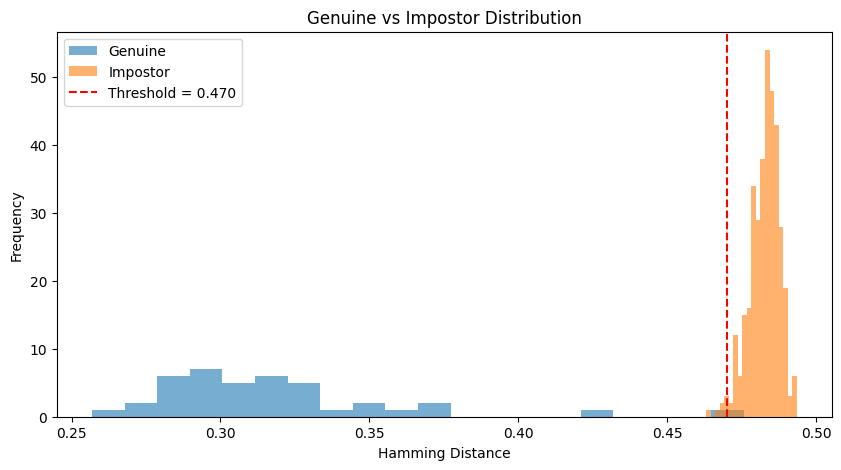

In [15]:
THRESHOLD = 0.470

plt.figure(figsize=(10, 5))

plt.hist(genuine, bins=20, alpha=0.6, label="Genuine")
plt.hist(impostor, bins=20, alpha=0.6, label="Impostor")

plt.axvline(
    THRESHOLD,
    color="red",
    linestyle="--",
    label=f"Threshold = {THRESHOLD:.3f}"
)

plt.xlabel("Hamming Distance")
plt.ylabel("Frequency")
plt.title("Genuine vs Impostor Distribution")
plt.legend()
plt.show()

In [16]:
authorized_users = [str(i) for i in range(100, 110)]

db_codes = []
db_owners = []

for user in authorized_users:
    for index in [1, 2]:
        stem = f"{user}_1_{index}"

        code = extract_iris_code(stem)

        db_codes.append(code)
        db_owners.append(user)

db_codes = np.stack(db_codes)
db_owners = np.array(db_owners)

database_path = ROOT / "iris_database.npz"

np.savez_compressed(
    database_path,
    codes=db_codes,
    owners=db_owners
)

print("Database created successfully")
print("Number of users:", len(authorized_users))
print("Number of templates:", len(db_codes))
print("Database shape:", db_codes.shape)

Database created successfully
Number of users: 10
Number of templates: 20
Database shape: (20, 64, 512, 2)


In [17]:
saved_database = np.load(database_path, allow_pickle=False)

db_codes = saved_database["codes"]
db_owners = saved_database["owners"]

print("Loaded successfully")
print("Users:", np.unique(db_owners))

Loaded successfully
Users: ['100' '101' '102' '103' '104' '105' '106' '107' '108' '109']


In [18]:

def authenticate(image_stem):
    query_code = extract_iris_code(image_stem)

    distances = []

    for template in db_codes:
        distance, shift = hamming_distance(
            query_code,
            template
        )

        distances.append((distance, shift))

    best_index = np.argmin([d[0] for d in distances])

    best_distance, best_shift = distances[best_index]
    matched_user = str(db_owners[best_index])

    if best_distance <= THRESHOLD:
        return {
            "status": "AUTHORIZED",
            "user": matched_user,
            "distance": best_distance,
            "shift": best_shift
        }

    return {
        "status": "UNAUTHORIZED",
        "user": None,
        "distance": best_distance,
        "shift": best_shift
    }
result = authenticate("100_1_3")

print("Status:", result["status"])
print("Matched User:", result["user"])
print("Hamming Distance:", result["distance"])
result = authenticate("110_1_3")

print("\nStatus:", result["status"])
print("Matched User:", result["user"])
print("Hamming Distance:", result["distance"])

Status: AUTHORIZED
Matched User: 100
Hamming Distance: 0.3091888427734375

Status: UNAUTHORIZED
Matched User: None
Hamming Distance: 0.4712982177734375


In [25]:
import ipywidgets as widgets
from IPython.display import display, clear_output

image_selector = widgets.Dropdown(
    options=sorted([
        p.stem for p in images
        if len(p.stem.split("_")) == 3 and p.stem.split("_")[1] == "1"
    ]),
    description="Eye Image:"
)
verify_button = widgets.Button(
    description="Verify Identity",
    button_style="success"
)

output = widgets.Output()

def verify_action(button):
    with output:
        clear_output()

        stem = image_selector.value
        result = authenticate(stem)

        img = cv2.imread(
            str(IMG_DIR / f"{stem}.jpg"),
            cv2.IMREAD_GRAYSCALE
        )

        plt.figure(figsize=(5, 4))
        plt.imshow(img, cmap="gray")
        plt.title(f"Input: {stem}")
        plt.axis("off")
        plt.show()

        print("IDENTITY VERIFICATION")
        print("---------------------")
        print("Status:", result["status"])
        print("Matched User:", result["user"])
        print("Hamming Distance:", round(result["distance"], 4))
        print("Rotation Shift:", result["shift"])

verify_button.on_click(verify_action)

display(image_selector, verify_button, output)

Dropdown(description='Eye Image:', options=('100_1_1', '100_1_2', '100_1_3', '100_1_4', '101_1_1', '101_1_2', …

Button(button_style='success', description='Verify Identity', style=ButtonStyle())

Output()

In [22]:
all_users = sorted(
    {p.stem.split("_")[0] for p in images},
    key=int
)

authorized_ids = set(authorized_users)

unknown_users = [
    user for user in all_users
    if user not in authorized_ids
][:10]

genuine_results = []
impostor_results = []

for user in authorized_users:
    for index in [3, 4]:
        stem = f"{user}_1_{index}"
        result = authenticate(stem)

        genuine_results.append({
            "input": stem,
            "expected": user,
            **result
        })

for user in unknown_users:
    for index in [3, 4]:
        stem = f"{user}_1_{index}"
        result = authenticate(stem)

        impostor_results.append({
            "input": stem,
            "expected": None,
            **result
        })

genuine_correct = sum(
    r["status"] == "AUTHORIZED" and r["user"] == r["expected"]
    for r in genuine_results
)

false_accept = sum(
    r["status"] == "AUTHORIZED"
    for r in impostor_results
)

false_reject = sum(
    r["status"] == "UNAUTHORIZED"
    for r in genuine_results
)

wrong_identity = sum(
    r["status"] == "AUTHORIZED" and r["user"] != r["expected"]
    for r in genuine_results
)

impostor_rejected = len(impostor_results) - false_accept

print("Genuine correct:", genuine_correct, "/", len(genuine_results))
print("Impostor rejected:", impostor_rejected, "/", len(impostor_results))
print("False Acceptance:", false_accept)
print("False Rejection:", false_reject)
print("Wrong Identity:", wrong_identity)

print("FAR:", false_accept / len(impostor_results))
print("FRR:", false_reject / len(genuine_results))


Genuine correct: 20 / 20
Impostor rejected: 18 / 20
False Acceptance: 2
False Rejection: 0
Wrong Identity: 0
FAR: 0.1
FRR: 0.0


In [23]:
false_accepts = [
    r for r in impostor_results
    if r["status"] == "AUTHORIZED"
]

print("FALSE ACCEPTANCE CASES")
print("----------------------")

for r in false_accepts:
    print("Input:", r["input"])
    print("Incorrectly matched:", r["user"])
    print("Distance:", round(r["distance"], 4))
    print()

FALSE ACCEPTANCE CASES
----------------------
Input: 1_1_3
Incorrectly matched: 104
Distance: 0.4615

Input: 2_1_4
Incorrectly matched: 108
Distance: 0.4692

